<div style="text-align:center; border-radius:20px; padding:25px; color:white; margin:0; font-family:sans-serif; background:#1b002a; box-shadow:0px 6px 18px rgba(0,0,0,0.35); margin-bottom:1em;">
          <div style="font-size:200%; color:#FEE100; font-weight:700;">
            indonesia-financial-time-series-dataset-2010-2026-ETL,EDA,Visualize,Model
          </div>
        </div>
        

![Dataset Image]((None, None))


In [1]:
import os
main_csv_local_path = 'Daily Multi-Asset Macroeconomic and Financial Time Series Dataset (IndonesiaGlobal Markets).csv'
DATA_DIR = ''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename == main_csv_local_path:
            DATA_DIR = os.path.join(dirname, filename)
            print(DATA_DIR)


/kaggle/input/datasets/raphaelnazareth/indonesia-financial-time-series-dataset-2010-2026/Daily Multi-Asset Macroeconomic and Financial Time Series Dataset (IndonesiaGlobal Markets).csv


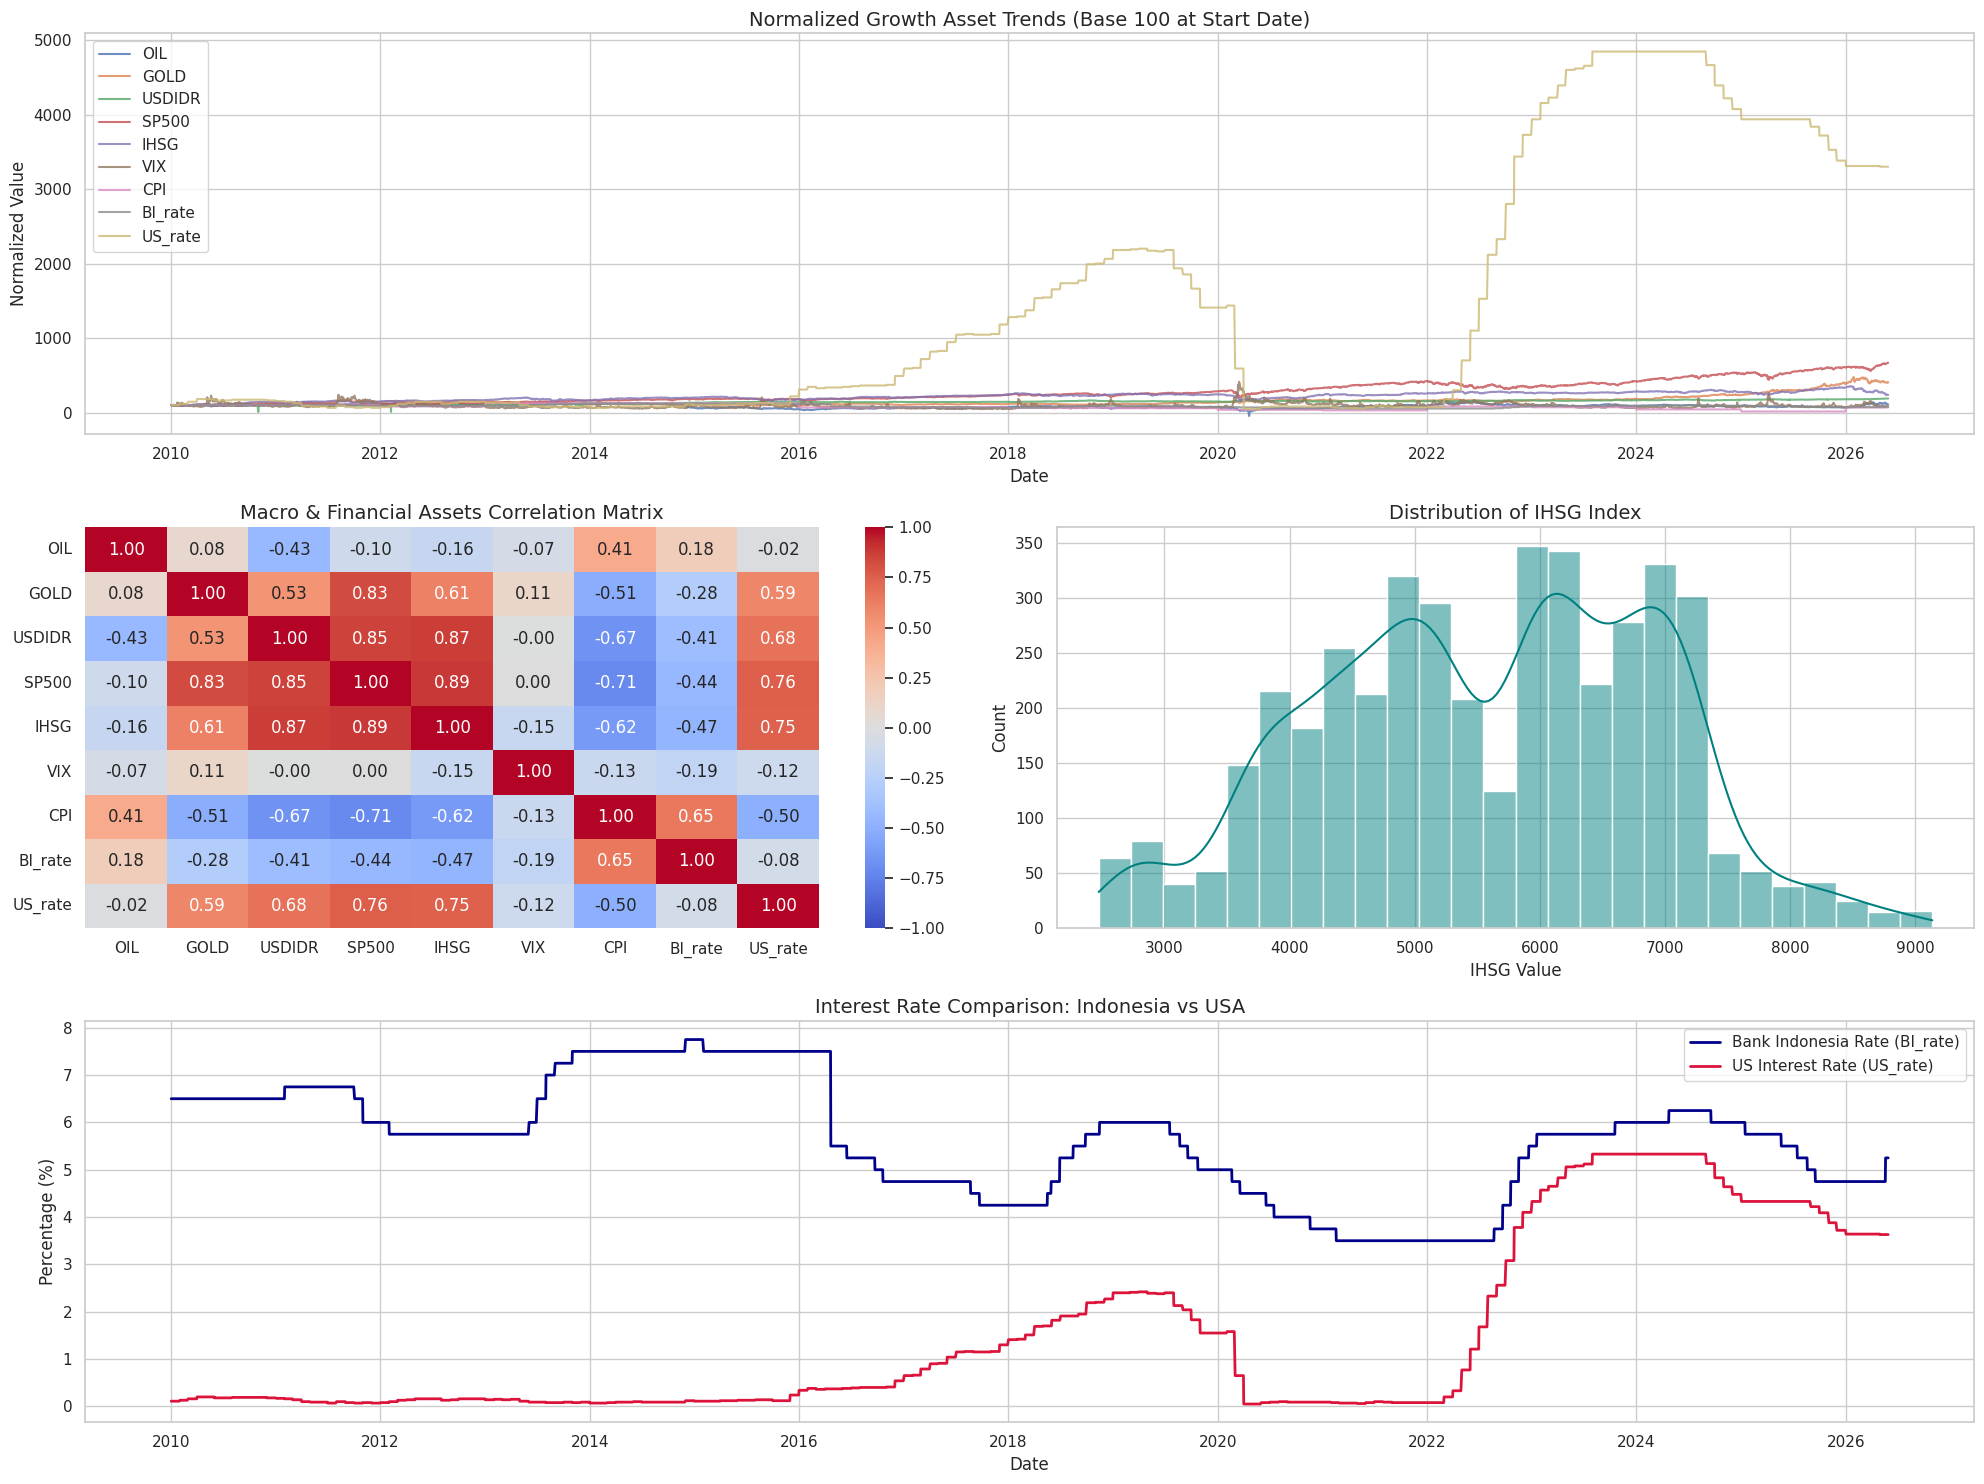

In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure DATA_DIR is used directly as specified by the environment
# load the data
df = pd.read_csv(DATA_DIR)

# ==========================================
# 1. ETL & CLEANING
# ==========================================

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Sort by date to preserve time-series structure
df = df.sort_values("Date").reset_index(drop=True)

# Select numerical columns for processing
num_cols = [
    "OIL",
    "GOLD",
    "USDIDR",
    "SP500",
    "IHSG",
    "VIX",
    "CPI",
    "BI_rate",
    "US_rate",
]

# Ensure all financial/macro columns are float numeric
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Handle missing values using forward fill (common for financial time series)
# followed by backward fill for any remaining initial NaNs
df[num_cols] = df[num_cols].ffill().bfill()

# ==========================================
# 2. EDA (Summary Stats & Correlations)
# ==========================================

# Generate summary statistics
summary_stats = df.describe()

# Calculate correlation matrix
corr_matrix = df[num_cols].corr()

# ==========================================
# 3. VISUALIZATION
# ==========================================

# Set up matplotlib/seaborn configuration
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(20, 15))

# Plot 1: Normalized Time Series Trend (to compare asset scales)
ax1 = plt.subplot2grid((3, 2), (0, 0), colspan=2)
# Normalize columns to 100 at the start of the time series for comparative visualization
normalized_df = df[num_cols].div(df[num_cols].iloc[0]).mul(100)
normalized_df["Date"] = df["Date"]
for col in num_cols:
    ax1.plot(normalized_df["Date"], normalized_df[col], label=col, alpha=0.8)
ax1.set_title(
    "Normalized Growth Asset Trends (Base 100 at Start Date)", fontsize=14
)
ax1.set_xlabel("Date")
ax1.set_ylabel("Normalized Value")
ax1.legend(loc="upper left")

# Plot 2: Correlation Heatmap
ax2 = plt.subplot2grid((3, 2), (1, 0))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    ax=ax2,
    cbar=True,
)
ax2.set_title("Macro & Financial Assets Correlation Matrix", fontsize=14)

# Plot 3: Distribution of IHSG (Indonesia Stock Market Index)
ax3 = plt.subplot2grid((3, 2), (1, 1))
sns.histplot(df["IHSG"], kde=True, ax=ax3, color="teal")
ax3.set_title("Distribution of IHSG Index", fontsize=14)
ax3.set_xlabel("IHSG Value")

# Plot 4: BI Rate vs US Rate (Interest Rate Comparison)
ax4 = plt.subplot2grid((3, 2), (2, 0), colspan=2)
ax4.plot(
    df["Date"],
    df["BI_rate"],
    label="Bank Indonesia Rate (BI_rate)",
    color="darkblue",
    linewidth=2,
)
ax4.plot(
    df["Date"],
    df["US_rate"],
    label="US Interest Rate (US_rate)",
    color="crimson",
    linewidth=2,
)
ax4.set_title("Interest Rate Comparison: Indonesia vs USA", fontsize=14)
ax4.set_xlabel("Date")
ax4.set_ylabel("Percentage (%)")
ax4.legend(loc="upper right")

plt.tight_layout()
plt.show()
